# U.S. Crude Oil Production Analysis | Python

### Weekly U.S. Field Production of Crude Oil — EIA Data

This notebook analyzes weekly U.S. field production of crude oil from the U.S. Energy Information Administration (EIA): data inspection, cleaning, KPIs, week-over-week changes, monthly averages, and visualizations.

**Source:** EIA Weekly Petroleum Status Report, series `WCRFPUS2` — U.S. Field Production of Crude Oil (Thousand Barrels per Day).

**Data:** an embedded snapshot of 20 weekly observations (May 15 – Sep 25, 2026). To pull the latest data instead, set the `EIA_API_KEY` environment variable (free key from eia.gov/opendata); the loading cell in Section 2 falls back to the snapshot if no key is set or the request fails.

## About this data (read before interpreting)

- **Weekly figures are estimates, not meter readings.** EIA estimates weekly domestic production from short-term forecasts for the Lower 48 states plus the latest Alaska data, and rounds to the nearest 1,000 b/d. Week-to-week "volatility" therefore partly reflects EIA's estimation process.
- **Re-benchmarking adjustments.** EIA may re-benchmark the weekly estimate in the week of its Short-Term Energy Outlook (STEO) release. EIA's Weekly Petroleum Status Report for the week ending **Sep 4, 2026** states that its figure includes a re-benchmarking adjustment of **+65,000 b/d**, so most of that week's +85 kb/d jump is a methodology step, not a physical change in output. Other large single-week steps may have the same cause; check the notes in each week's report at eia.gov/petroleum/supply/weekly/.
- **Short window.** 20 weeks is enough to describe the recent trend but not to draw seasonal or year-over-year conclusions.
- **Scope.** Crude oil (including lease condensate) only; this notebook does not cover natural gas.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load EIA Data

The cell below defines an embedded snapshot of the EIA weekly series. If `EIA_API_KEY` is set, it tries the EIA API v2 first and uses the snapshot only as a fallback, so the notebook always runs offline.

In [2]:
import os
import requests

# Embedded snapshot of EIA series WCRFPUS2 (thousand barrels per day), week ending Friday
snapshot = [
    ("2026-05-15", 13702), ("2026-05-22", 13715), ("2026-05-29", 13707),
    ("2026-06-05", 13799), ("2026-06-12", 13806), ("2026-06-19", 13819),
    ("2026-06-26", 13810), ("2026-07-03", 13860), ("2026-07-10", 13861),
    ("2026-07-17", 13798), ("2026-07-24", 13796), ("2026-07-31", 13804),
    ("2026-08-07", 13805), ("2026-08-14", 13830), ("2026-08-21", 13843),
    ("2026-08-28", 13862), ("2026-09-04", 13947), ("2026-09-11", 13944),
    ("2026-09-18", 13939), ("2026-09-25", 13955),
]

def load_from_api(api_key, n_weeks=20):
    """Latest n_weeks of WCRFPUS2 from the EIA API v2."""
    r = requests.get(
        "https://api.eia.gov/v2/petroleum/sum/sndw/data/",
        params={
            "api_key": api_key,
            "frequency": "weekly",
            "data[0]": "value",
            "facets[series][]": "WCRFPUS2",
            "sort[0][column]": "period",
            "sort[0][direction]": "desc",
            "length": n_weeks,
        },
        timeout=30,
    )
    r.raise_for_status()
    rows = r.json()["response"]["data"]
    out = pd.DataFrame(rows)[["period", "value"]]
    out.columns = ["Date", "Oil_Production_MBBL_D"]
    out["Oil_Production_MBBL_D"] = pd.to_numeric(out["Oil_Production_MBBL_D"])
    return out

df, data_source = None, "embedded snapshot"
api_key = os.environ.get("EIA_API_KEY")
if api_key:
    try:
        df = load_from_api(api_key)
        data_source = "EIA API v2"
    except Exception as e:
        print(f"API request failed ({e}); using embedded snapshot.")

if df is None:
    df = pd.DataFrame(snapshot, columns=["Date", "Oil_Production_MBBL_D"])

df["Date"] = pd.to_datetime(df["Date"])
print("Data source:", data_source)
df.head()

Data source: embedded snapshot


,Date,Oil_Production_MBBL_D
0,2026-05-15,13702
1,2026-05-22,13715
2,2026-05-29,13707
3,2026-06-05,13799
4,2026-06-12,13806


## 3. Inspect and Clean the Data

In [3]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

df = df.drop_duplicates(subset=["Date"]).sort_values("Date").reset_index(drop=True)

print("\nCleaned shape:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   20 non-null     datetime64[us]
 1   Oil_Production_MBBL_D  20 non-null     int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 452.0 bytes

Missing values:
Date                     0
Oil_Production_MBBL_D    0
dtype: int64

Cleaned shape: (20, 2)


In [4]:
df.describe()

,Date,Oil_Production_MBBL_D
count,20,20.000000
mean,2026-07-20 12:00:00,13830.100000
min,2026-05-15 00:00:00,13702.000000
25%,2026-06-17 06:00:00,13798.750000
50%,2026-07-20 12:00:00,13814.500000
75%,2026-08-22 18:00:00,13861.250000
max,2026-09-25 00:00:00,13955.000000
std,NaN,75.226605


## 4. Week-over-Week Production Change

In [5]:
df["WoW_Change_%"] = df["Oil_Production_MBBL_D"].pct_change() * 100

df.tail()

,Date,Oil_Production_MBBL_D,WoW_Change_%
15,2026-08-28,13862,0.137253
16,2026-09-04,13947,0.613187
17,2026-09-11,13944,-0.021510
18,2026-09-18,13939,-0.035858
19,2026-09-25,13955,0.114786


## 5. Monthly Average Production

Months are assigned by week-ending date. Check `Weeks_Observed`: months with fewer than four observations (the first month in the sample, for instance) are partial and not directly comparable to full months.

In [6]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_production = (
    df.groupby("Month")
      .agg(
          Oil_Production_MBBL_D=("Oil_Production_MBBL_D", "mean"),
          Weeks_Observed=("Date", "count"),
      )
      .reset_index()
)

monthly_production["Month"] = monthly_production["Month"].astype(str)

monthly_production

,Month,Oil_Production_MBBL_D,Weeks_Observed
0,2026-05,13708.00,3
1,2026-06,13808.50,4
2,2026-07,13823.80,5
3,2026-08,13835.00,4
4,2026-09,13946.25,4


## 6. Key Business KPIs

In [7]:
kpis = pd.DataFrame({
    "Metric": [
        "Latest Production",
        "Average Production",
        "Maximum Production",
        "Minimum Production",
        "Average Weekly Change",
        "Std. Dev. of Weekly Change",
    ],
    "Value": [
        round(df["Oil_Production_MBBL_D"].iloc[-1], 2),
        round(df["Oil_Production_MBBL_D"].mean(), 2),
        round(df["Oil_Production_MBBL_D"].max(), 2),
        round(df["Oil_Production_MBBL_D"].min(), 2),
        round(df["WoW_Change_%"].mean(), 2),
        round(df["WoW_Change_%"].std(), 2),
    ],
    "Unit": ["kb/d", "kb/d", "kb/d", "kb/d", "%", "%"],
})

kpis

,Metric,Value,Unit
0,Latest Production,13955.00,kb/d
1,Average Production,13830.10,kb/d
2,Maximum Production,13955.00,kb/d
3,Minimum Production,13702.00,kb/d
4,Average Weekly Change,0.10,%
5,Std. Dev. of Weekly Change,0.25,%


## 7. Visualization — Oil Production Trend

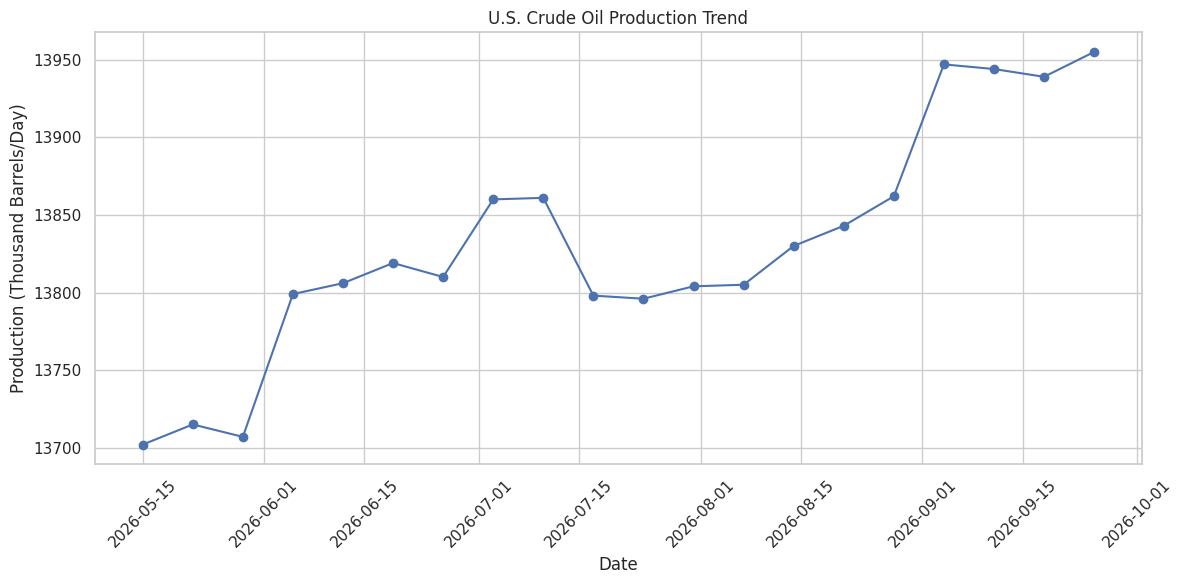

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["Oil_Production_MBBL_D"], marker="o")
plt.title("U.S. Crude Oil Production Trend")
plt.xlabel("Date")
plt.ylabel("Production (Thousand Barrels/Day)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Visualization — Monthly Average Production

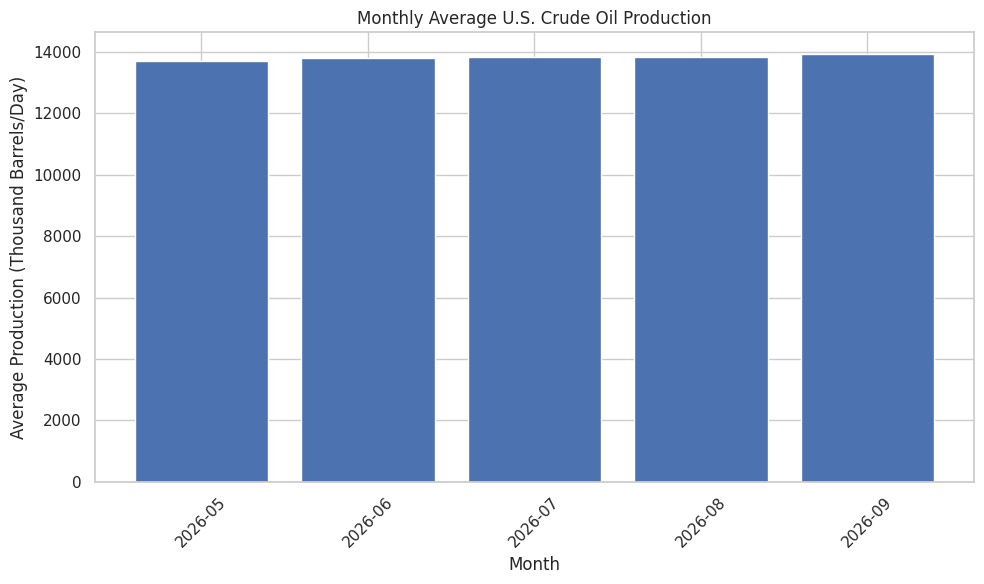

In [9]:
plt.figure(figsize=(10, 6))
plt.bar(monthly_production["Month"], monthly_production["Oil_Production_MBBL_D"])
plt.title("Monthly Average U.S. Crude Oil Production")
plt.xlabel("Month")
plt.ylabel("Average Production (Thousand Barrels/Day)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Visualization — Week-over-Week Change

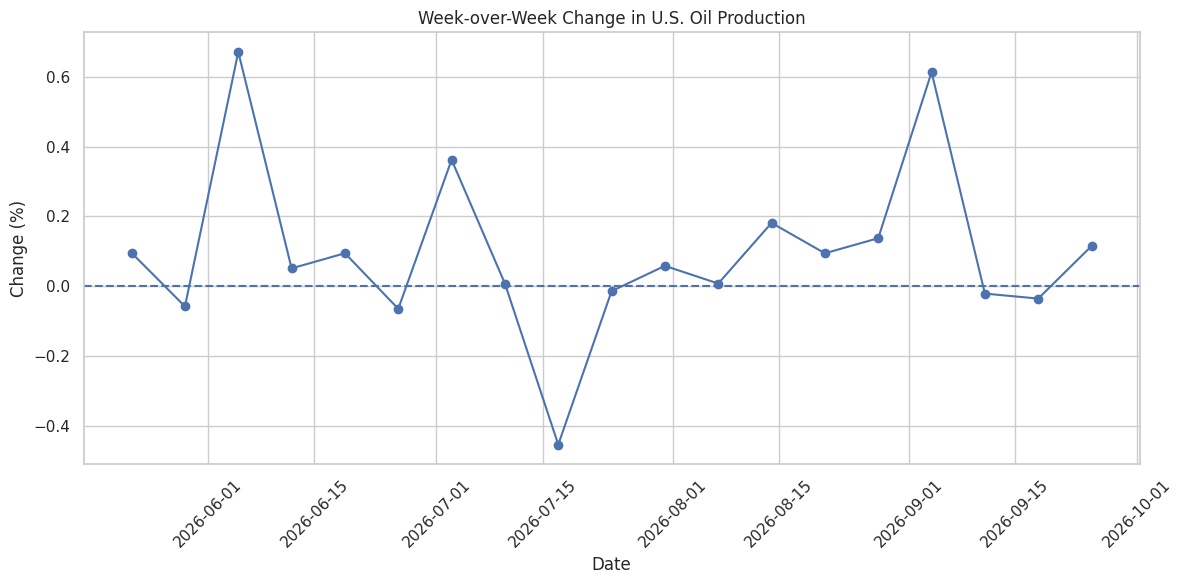

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["WoW_Change_%"], marker="o")
plt.axhline(0, linestyle="--")
plt.title("Week-over-Week Change in U.S. Oil Production")
plt.xlabel("Date")
plt.ylabel("Change (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10. Largest Production Increases

> **Note:** the Sep 4 increase includes a +65 kb/d EIA re-benchmarking adjustment (see "About this data"), so it should not be read as a physical production surge.

In [11]:
df[
    ["Date", "Oil_Production_MBBL_D", "WoW_Change_%"]
].dropna().sort_values("WoW_Change_%", ascending=False).head(10)

,Date,Oil_Production_MBBL_D,WoW_Change_%
3,2026-06-05,13799,0.671190
16,2026-09-04,13947,0.613187
7,2026-07-03,13860,0.362056
13,2026-08-14,13830,0.181094
15,2026-08-28,13862,0.137253
19,2026-09-25,13955,0.114786
1,2026-05-22,13715,0.094877
5,2026-06-19,13819,0.094162
14,2026-08-21,13843,0.093999
11,2026-07-31,13804,0.057988


## 11. Largest Production Declines

Only weeks with a negative week-over-week change are shown.

In [12]:
declines = (
    df.loc[df["WoW_Change_%"] < 0, ["Date", "Oil_Production_MBBL_D", "WoW_Change_%"]]
      .sort_values("WoW_Change_%")
      .head(10)
)
print(f"{len(declines)} of {df['WoW_Change_%'].notna().sum()} weekly changes were declines.")
declines

6 of 19 weekly changes were declines.


,Date,Oil_Production_MBBL_D,WoW_Change_%
9,2026-07-17,13798,-0.454513
6,2026-06-26,13810,-0.065128
2,2026-05-29,13707,-0.058330
18,2026-09-18,13939,-0.035858
17,2026-09-11,13944,-0.021510
10,2026-07-24,13796,-0.014495


## 12. Latest Available Production

In [13]:
latest = df.iloc[-1]

print("Latest available date:", latest["Date"].date())
print("Latest production:", round(latest["Oil_Production_MBBL_D"], 2), "thousand barrels/day")
print("Week-over-week change:", round(latest["WoW_Change_%"], 2), "%")

Latest available date: 2026-09-25
Latest production: 13955 thousand barrels/day
Week-over-week change: 0.11 %


## 13. Business Insights

Computed directly from the data above, so the text stays correct if the data is refreshed.

In [14]:
prod = df["Oil_Production_MBBL_D"]
first, last = prod.iloc[0], prod.iloc[-1]
net_change = last - first
changes = prod.diff().dropna()
n_up = int((changes > 0).sum())
n_down = int((changes < 0).sum())
positive_change = changes[changes > 0].sum()
negative_change = changes[changes < 0].sum()
biggest_drop_date = df.loc[changes.idxmin(), "Date"].date()

print("U.S. CRUDE OIL PRODUCTION — KEY TAKEAWAYS")
print("=" * 60)
print(
    f"1. Production changed from {first:,.0f} to {last:,.0f} kb/d between "
    f"{df['Date'].iloc[0].date()} and {df['Date'].iloc[-1].date()}: "
    f"{net_change:+,.0f} kb/d ({net_change / first * 100:+.2f}%)."
)
print(
    f"2. {n_up} of {len(changes)} weekly intervals recorded increases and "
    f"{n_down} recorded declines. Total positive weekly movement was "
    f"{positive_change:+,.0f} kb/d, while total negative movement was "
    f"{negative_change:+,.0f} kb/d."
)
print(
    f"3. The largest weekly decline was {changes.min():+,.0f} kb/d "
    f"(week ending {biggest_drop_date})."
)
print(
    f"4. Latest reading ({last:,.0f} kb/d) is also the sample maximum: "
    f"{last == prod.max()}."
)
print(
    f"5. Typical weekly move: mean {df['WoW_Change_%'].mean():+.2f}%, "
    f"std. dev. {df['WoW_Change_%'].std():.2f}%."
)
print(
    "\nCaveat: weekly values are EIA estimates (rounded to 1,000 b/d), "
    "and the Sep 4 week includes a +65 kb/d re-benchmarking adjustment per EIA."
)

U.S. CRUDE OIL PRODUCTION — KEY TAKEAWAYS
1. Production changed from 13,702 to 13,955 kb/d between 2026-05-15 and 2026-09-25: +253 kb/d (+1.85%).
2. 13 of 19 weekly intervals recorded increases and 6 recorded declines. Total positive weekly movement was +343 kb/d, while total negative movement was -90 kb/d.
3. The largest weekly decline was -63 kb/d (week ending 2026-07-17).
4. Latest reading (13,955 kb/d) is also the sample maximum: True.
5. Typical weekly move: mean +0.10%, std. dev. 0.25%.

Caveat: weekly values are EIA estimates (rounded to 1,000 b/d), and the Sep 4 week includes a +65 kb/d re-benchmarking adjustment per EIA.


## 14. Export Results

In [15]:
df.to_csv("oil_production_cleaned.csv", index=False)
monthly_production.to_csv("monthly_oil_production.csv", index=False)
kpis.to_csv("oil_production_kpis.csv", index=False)

print("CSV files exported successfully.")

CSV files exported successfully.


## Conclusion

This notebook walks through a complete Python analytics workflow:

**EIA data → Data cleaning → KPI calculation → Trend & change analysis → Visualization → Takeaways**

Over the 20-week window, estimated U.S. crude oil production rose, with increases in most weeks and one notably large step in the week ending Sep 4, which EIA says includes a re-benchmarking adjustment. Because EIA's weekly figures are model-based estimates that are periodically re-benchmarked, the results describe the *reported series*, not directly measured output.

Source series: EIA `WCRFPUS2` — U.S. Field Production of Crude Oil (thousand barrels per day).

**Possible extensions:** add a longer history for year-over-year comparison; compare with the monthly EIA-914 production data; overlay WTI prices or rig counts; add natural gas production.